In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np, pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.feature_selection import mutual_info_classif

from optbinning import OptimalBinning

from pathlib import Path

from IPython.display import display, clear_output

In [2]:
PATHFILE = Path.cwd().parent / 'data' / 'raw' / 'cs-training.csv'
TARGET_NAME = 'SeriousDlqin2yrs'

BN = '-'*70 # "barra n", para poder separar as análises

**Levantamento dados de treino da base**<br>
Aqui vamos usar base já splitada cs-training, disponível em data/raw a partir da extração feita pelo makefile dos dados da competição _Can you give me some credit_.

In [3]:
''' 
- Extração dos dados de treino 150k instâncias, 10 features numéricas, 1 alvo binário
- Dados faltantes nas features MonthlyIncome e NumberOfDependents
'''

train_df_raw = pd.read_csv(PATHFILE, index_col=0)

train_df = train_df_raw.copy()
display(train_df.head(1))

train_df.info()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0


<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

In [19]:
print('''Análise da coluna RevolvingUtilizationOfUnsecuredLines (razao uso 
rotativo pela soma do limite de crédito)''')

uso_rotativo = train_df_raw.RevolvingUtilizationOfUnsecuredLines

print(BN, '''\nDesbalanceada, maior parte dos clientes nunca usou rotativo.
Maiores valores não são compatíveis, provável erro na base.''')
display(uso_rotativo.value_counts().sort_index())

print(BN, '''\n99% dos valores estão abaixo de 1,1. Valores extremos de 1000 até
50708 aparecem em uma minoria dos casos.''')
display(uso_rotativo.quantile([0.9, 0.95, 0.99, 0.999, 0.9999, 1.0]))

print(BN, '''\nA partir de 4, a redução no número de linhas é gradual. Vou tomar a
decisão de considerar uso maior que 400% como erro.''')
for limite in [1,2,3,4,5,10,20,50,100]:
    n = (uso_rotativo > limite).sum()
    print(f'> {limite}: {n} linhas')

# TODO: implementar tratamento sobre RevolvingUtilizationOfUnsecuredLines na pipeline
train_df.loc[uso_rotativo > 4, 'RevolvingUtilizationOfUnsecuredLines'] = np.nan

Análise da coluna RevolvingUtilizationOfUnsecuredLines (razao uso 
rotativo pela soma do limite de crédito)
---------------------------------------------------------------------- 
Desbalanceada, maior parte dos clientes nunca usou rotativo.
Maiores valores não são compatíveis, provável erro na base.


RevolvingUtilizationOfUnsecuredLines
0.000000        10878
0.000008            1
0.000010            1
0.000013            1
0.000014            1
                ...  
20514.000000        1
22000.000000        1
22198.000000        1
29110.000000        1
50708.000000        1
Name: count, Length: 125728, dtype: int64

---------------------------------------------------------------------- 
99% dos valores estão abaixo de 1,1. Valores extremos de 1000 até
50708 aparecem em uma minoria dos casos.


0.9000        0.981278
0.9500        1.000000
0.9900        1.092956
0.9990     1571.006000
0.9999    10151.005800
1.0000    50708.000000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

---------------------------------------------------------------------- 
A partir de 4, a redução no número de linhas é gradual. Vou tomar a
decisão de considerar uso maior que 400% como erro.
> 1: 3321 linhas
> 2: 371 linhas
> 3: 292 linhas
> 4: 264 linhas
> 5: 254 linhas
> 10: 241 linhas
> 20: 234 linhas
> 50: 230 linhas
> 100: 223 linhas


---------------------------------------------------------------------- 
Não deveria aparecer menores de idade na base (muito menos
um recém nacido).


65696    0
Name: age, dtype: int64

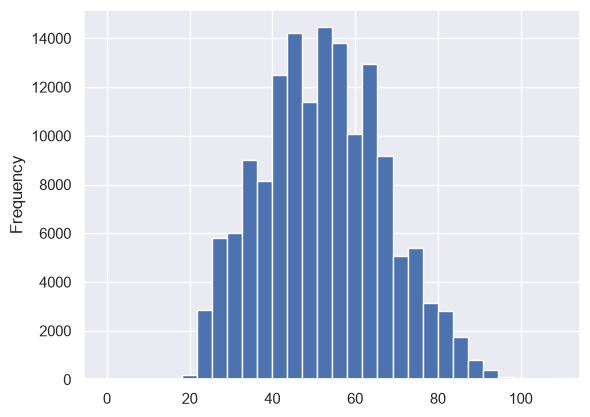

In [16]:
'''
Análise sobre feature age
'''

idades = train_df_raw.age

idades.plot(kind='hist', bins=30)

print(BN, '''\nNão deveria aparecer menores de idade na base (muito menos
um recém nacido).''')
display(idades[idades < 18])

# TODO: implementar tratamento da idade na pipeline
train_df.loc[idades == 0, 'age'] = np.nan

In [ ]:
# Valores 96 e 98 destoam muito. Vou considerar eles como erros
train_df['NumberOfTime30-59DaysPastDueNotWorse'].value_counts().sort_index(ascending=False)

NumberOfTime30-59DaysPastDueNotWorse
98       264
96         5
13         1
12         2
11         1
10         4
9         12
8         25
7         54
6        140
5        342
4        747
3       1754
2       4598
1      16033
0     126018
Name: count, dtype: int64

In [11]:
# Mesmo tratamento de "NumberOfTime30-59DaysPastDueNotWorse"
train_df['NumberOfTimes90DaysLate'].value_counts().sort_index(ascending=False)

NumberOfTimes90DaysLate
98       264
96         5
17         1
15         2
14         2
13         4
12         2
11         5
10         8
9         19
8         21
7         38
6         80
5        131
4        291
3        667
2       1555
1       5243
0     141662
Name: count, dtype: int64

In [12]:
# Mesmo tratamento de "NumberOfTime30-59DaysPastDueNotWorse"
train_df['NumberOfTime60-89DaysPastDueNotWorse'].value_counts().sort_index(ascending=False)

NumberOfTime60-89DaysPastDueNotWorse
98       264
96         5
11         1
9          1
8          2
7          9
6         16
5         34
4        105
3        318
2       1118
1       5731
0     142396
Name: count, dtype: int64

In [13]:
# Apesar dos valores extremos, distribuição está conforme esperado
train_df['NumberOfDependents'].value_counts()

NumberOfDependents
0.0     86902
1.0     26316
2.0     19522
3.0      9483
4.0      2862
5.0       746
6.0       158
7.0        51
8.0        24
10.0        5
9.0         5
20.0        1
13.0        1
Name: count, dtype: int64

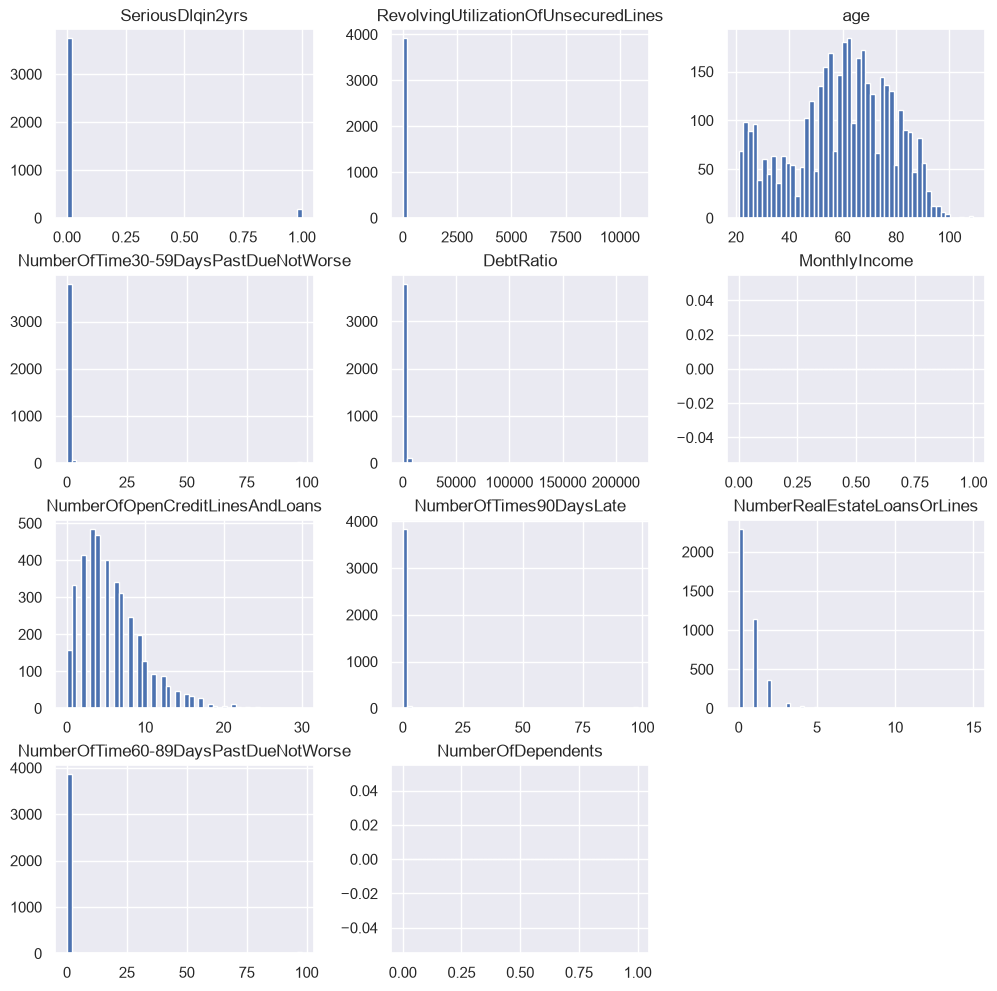

In [14]:
''' Comecei a fazer análise para os registros com NumberOfDependents nulos, e 
MonthlyIncome tem padrão de não aparecerem dados juntos também
'''
train_df[train_df.NumberOfDependents.isna()].hist(bins=50, figsize=(12, 12));

In [15]:
''' Todos os registros com NumberOfDependents nulos tem MonthlyIncome nulo
também. O contrário acaba não acontecendo (86% dos registros com MI vazios
tem NumberOfDependents preenchidos)
'''

dep_NA = train_df.NumberOfDependents.isna()
MI_NA = train_df.MonthlyIncome.isna()

print(train_df[dep_NA].MonthlyIncome.isna().all())
print(train_df[MI_NA].NumberOfDependents.isna().all())
(1 - train_df[MI_NA].NumberOfDependents.isna()).sum() / len(train_df[MI_NA])

True
False


np.float64(0.8680165483838418)

In [16]:
'''O NumberOfDependents não preenchido tem maior tendência para inadimplência
É preciso criar coluna sinalizando 
'''

pd.crosstab(train_df.NumberOfDependents.isna(), train_df.SeriousDlqin2yrs,
            normalize='index')

SeriousDlqin2yrs,0,1
NumberOfDependents,,
False,0.932590,0.067410
True,0.954383,0.045617


In [17]:
'''O MonthlyIncome não preenchido tem maior tendência para inadimplência
É preciso criar coluna sinalizando 
'''

pd.crosstab(train_df.MonthlyIncome.isna(), train_df.SeriousDlqin2yrs,
            normalize='index')

SeriousDlqin2yrs,0,1
MonthlyIncome,,
False,0.930514,0.069486
True,0.943863,0.056137


<Axes: >

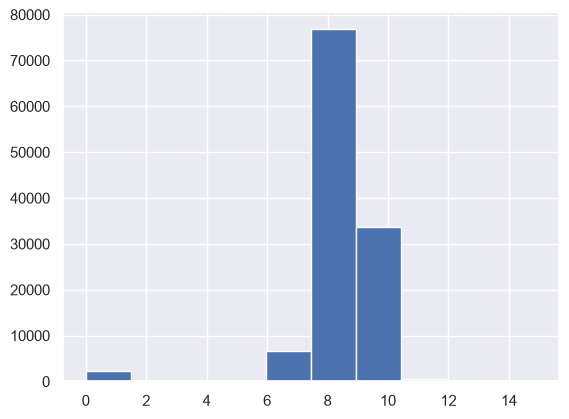

In [18]:
# Reduzindo cauda longa do MonthlyIncome para visualização
# dependendo do modelo vale incluir no pipeline
np.log1p(train_df['MonthlyIncome']).hist()

In [76]:
# Apesar dos valores extremos, distribuição está dentro do esperado
train_df.NumberRealEstateLoansOrLines.value_counts().sort_index()

NumberRealEstateLoansOrLines
0     56188
1     52338
2     31522
3      6300
4      2170
5       689
6       320
7       171
8        93
9        78
10       37
11       23
12       18
13       15
14        7
15        7
16        4
17        4
18        2
19        2
20        2
21        1
23        2
25        3
26        1
29        1
32        1
54        1
Name: count, dtype: int64

In [77]:
# Cauda longa
train_df['NumberOfOpenCreditLinesAndLoans'].value_counts().sort_index(ascending=False)

NumberOfOpenCreditLinesAndLoans
58        1
57        2
56        2
54        4
53        1
52        3
51        2
50        2
49        4
48        6
47        2
46        3
45        8
44        2
43        8
42        8
41        4
40       10
39        9
38       13
37        7
36       18
35       27
34       35
33       47
32       52
31       74
30       88
29      114
28      150
27      194
26      239
25      337
24      422
23      533
22      685
21      864
20     1169
19     1433
18     1874
17     2370
16     3000
15     3645
14     4546
13     5667
12     7005
11     8321
10     9624
9     11355
8     12562
7     13245
6     13614
5     12931
4     11609
3      9058
2      6666
1      4438
0      1888
Name: count, dtype: int64

In [78]:
# Nem sempre número de linhas de crédito está associado com alta renda
train_df.query('NumberOfOpenCreditLinesAndLoans > 40')['MonthlyIncome'].dropna().sort_values().head(15)

114364    2769.0
22684     3600.0
55656     4000.0
96374     4166.0
127754    4568.0
116162    5000.0
51393     5000.0
46829     5000.0
38134     5271.0
74031     5284.0
66980     5416.0
87103     5416.0
99883     5500.0
59044     5833.0
141523    6100.0
Name: MonthlyIncome, dtype: float64

In [79]:
train_df['DebtRatio'].quantile([0.5, .8, .85, 0.9, 0.99, 1])

0.50         0.366508
0.80         4.000000
0.85       269.150000
0.90      1267.000000
0.99      4979.040000
1.00    329664.000000
Name: DebtRatio, dtype: float64

In [80]:
for limite in [10, 20, 50, 100, 1000, 10000]:
    print(f'{limite}: {len(train_df.query('DebtRatio > @limite'))}')

10: 28877
20: 27862
50: 25934
100: 24380
1000: 16892
10000: 180


In [81]:
'''Tem uma associação direta com alta taxa de débito com MonthlyIncome faltante
'''

pd.crosstab(train_df.DebtRatio > 10, train_df.MonthlyIncome.isna())

MonthlyIncome,False,True
DebtRatio,,
False,118163,2960
True,2106,26771


In [82]:
'''Hipótese aqui que quando MonthlyIncome é nulo, DebtRatio possa estar alterado. Vou
seguir derrubando esses valores, mas vale avaliar impacto no modelo
'''

train_df.query('MonthlyIncome.isna()').DebtRatio.quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

0.25     123.0
0.50    1159.0
0.75    2382.0
0.90    3785.0
0.95    4902.5
0.99    8084.5
Name: DebtRatio, dtype: float64

In [83]:
def limpar_sujeiras(df):
       df = df.copy()
       df.loc[df['age'] == 0, 'age'] = np.nan
       df.loc[df['RevolvingUtilizationOfUnsecuredLines'] > 5, 
                 'RevolvingUtilizationOfUnsecuredLines'] = np.nan

       cols_atraso = [
              "NumberOfTime30-59DaysPastDueNotWorse",
              'NumberOfTime60-89DaysPastDueNotWorse',
              'NumberOfTimes90DaysLate'
       ]
       mask_atraso = df[cols_atraso].isin([96, 98])
       df[mask_atraso] = np.nan

       df.loc[df.MonthlyIncome.isna(), 'DebtRatio'] = np.nan
    
       return df

In [84]:
train_df = limpar_sujeiras(train_df)

In [85]:
def indicador_faltante(df, *cols):
    for col in cols:
        df[col+'_na'] = df[col].isna()
    return df

In [86]:
# Transformação 1 - impute
cols_faltantes = ['MonthlyIncome', 'NumberOfDependents', 'DebtRatio', 'age',
                  'RevolvingUtilizationOfUnsecuredLines', "NumberOfTime30-59DaysPastDueNotWorse",
                  'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfTimes90DaysLate']
imputer = SimpleImputer(strategy='median', add_indicator=True)
resultado = pd.DataFrame(imputer.fit_transform(train_df[cols_faltantes]),
                         columns=imputer.get_feature_names_out(),
                         index=train_df.index)
train_df = train_df.drop(cols_faltantes, axis=1).join(resultado)

In [87]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 19 columns):
 #   Column                                                 Non-Null Count   Dtype  
---  ------                                                 --------------   -----  
 0   SeriousDlqin2yrs                                       150000 non-null  int64  
 1   NumberOfOpenCreditLinesAndLoans                        150000 non-null  int64  
 2   NumberRealEstateLoansOrLines                           150000 non-null  int64  
 3   MonthlyIncome                                          150000 non-null  float64
 4   NumberOfDependents                                     150000 non-null  float64
 5   DebtRatio                                              150000 non-null  float64
 6   age                                                    150000 non-null  float64
 7   RevolvingUtilizationOfUnsecuredLines                   150000 non-null  float64
 8   NumberOfTime30-59DaysPastDueNotWorse         

---

### 
Status até aqui: dados extraídos e sujeiras tratadas (age, RevolvingUtilization, atrasos, DebtRatio). Imputação aplicada com indicadores separados por origem do nulo. Próximo passo: correlação entre features e com o target, antes de decidir engenharia adicional.

In [88]:
testes = (
    train_df.copy()
    .assign(_soma_atrasos = lambda df: # A correlação dessa coluna sempre fica menor que a correlação de df['NumberOfTime30-59DaysPastDueNotWorse'], aumentando conforme coeficiente que acompanha essa feature aumenta com relação aos demais, e diminuindo no caso de outras combinações
            3*df['NumberOfTime30-59DaysPastDueNotWorse']+
            2*df['NumberOfTimes90DaysLate']+
            df['NumberOfTime60-89DaysPastDueNotWorse'])
    .assign(_dependentes_por_idade = lambda df: # Pensei que poderia ser significativo pois baixa idade e alto número de dependentes poderia indicar endividamento futuro, mas correlação ficou aquém da correlação de idade sozinha, não parece ser atributo interessante.
            df['NumberOfDependents']/df['age'])
    .assign(_debito_a_renda = lambda df: # Aqui considerei que proporção de débito indicaria tendência maior ao endividamento caso a renda fosse mais alta, visto que a dívida seria maior e portanto mais difícil de contornar
            df['DebtRatio']*df['MonthlyIncome'])
    .assign(_rotativo_para_outros_custos = lambda df: # Aqui pensei em considerar proporção para quantidade de linhas de rotativo sobre quantidade de crédito imobiliário, pois o primeiro indicaria tendência ao endividamento e, caso o segundo fosse pequeno/nulo, estaria ocorrendo endividamento sem fundos. Mas a correlação parece baixa
            df['RevolvingUtilizationOfUnsecuredLines']/(df['NumberRealEstateLoansOrLines']+1))
    .assign(_rotativo_por_linhas_credito = lambda df: # Considerei aqui a proporção do uso do rotativo ao uso de linhas de crédito, indicando tendência ao uso do rotativo para empréstimos
            df['RevolvingUtilizationOfUnsecuredLines']/df['NumberOfOpenCreditLinesAndLoans'])
    .assign(_renda_por_idade = lambda df:
            df['MonthlyIncome']/df['age'])
)

In [154]:
'''
Tem a mesma informação  missingindicator_NumberOfTime30-59DaysPastDueNotWorse,
                        missingindicator_NumberOfTime60-89DaysPastDueNotWorse,
                        missingindicator_NumberOfTimes90DaysLate
Tem a mesma informação  missingindicator_MonthlyIncome
                        missingindicator_DebtRatio
'''

corr_mat = testes.corr()
resultado = (
    corr_mat[['SeriousDlqin2yrs']]
    .assign(sinal=lambda df: np.where(df['SeriousDlqin2yrs']>0,'+','-'))
    .assign(abs_corr=lambda df: np.abs(df.SeriousDlqin2yrs))
    .sort_values('abs_corr', ascending=False)
    .drop('SeriousDlqin2yrs', axis=1)
)
resultado

,sinal,abs_corr
SeriousDlqin2yrs,+,1.000000
_soma_atrasos,+,0.364028
NumberOfTimes90DaysLate,+,0.311713
RevolvingUtilizationOfUnsecuredLines,+,0.283483
NumberOfTime30-59DaysPastDueNotWorse,+,0.271411
NumberOfTime60-89DaysPastDueNotWorse,+,0.265594
_rotativo_para_outros_custos,+,0.261487
_rotativo_por_linhas_credito,+,0.176535
age,-,0.115397
WOE-age,-,0.109286


In [91]:
corr_mat = testes.corr(method='spearman')
resultado = (
    corr_mat[['SeriousDlqin2yrs']]
    .assign(sinal=lambda df: np.where(df['SeriousDlqin2yrs']>0,'+','-'))
    .assign(abs_corr=lambda df: np.abs(df.SeriousDlqin2yrs))
    .sort_values('abs_corr', ascending=False)
    .drop('SeriousDlqin2yrs', axis=1)
)
resultado

,sinal,abs_corr
SeriousDlqin2yrs,+,1.000000
NumberOfTimes90DaysLate,+,0.332203
_soma_atrasos,+,0.326038
NumberOfTime60-89DaysPastDueNotWorse,+,0.265617
NumberOfTime30-59DaysPastDueNotWorse,+,0.248156
RevolvingUtilizationOfUnsecuredLines,+,0.240798
_rotativo_para_outros_custos,+,0.224849
_rotativo_por_linhas_credito,+,0.208251
age,-,0.117038
missingindicator_NumberOfTime30-59DaysPastDueNotWorse,+,0.081401


<Axes: xlabel='NumberOfTimes90DaysLate'>

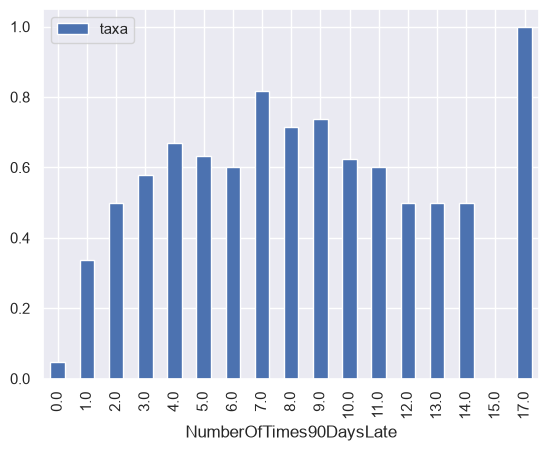

In [147]:
(testes[['NumberOfTimes90DaysLate', 'SeriousDlqin2yrs']]
 .groupby('NumberOfTimes90DaysLate')
 .agg(taxa=('SeriousDlqin2yrs', 'mean'), n=('SeriousDlqin2yrs', 'count'))
 [['taxa']]
 .plot(kind='bar'))

In [153]:
(
    testes
    [['NumberOfTimes90DaysLate', 'SeriousDlqin2yrs']]
    .groupby('NumberOfTimes90DaysLate')
    .agg(taxa=('SeriousDlqin2yrs', 'mean'), n=('SeriousDlqin2yrs', 'sum'))
)

,taxa,n
NumberOfTimes90DaysLate,,
0.0,0.047213,6701
1.0,0.336639,1765
2.0,0.499035,776
3.0,0.577211,385
4.0,0.670103,195
5.0,0.633588,83
6.0,0.600000,48
7.0,0.815789,31
8.0,0.714286,15


In [95]:
testes.age.quantile([0.05, 0.25, .5, 0.75, 0.9, 0.99]) # se eu fizer por quantiles, é possível que eu tenha grupos de idade super-representados, perdendo informação sobre como jovens podem ser maus pagadores por exemplo

0.05    29.0
0.25    41.0
0.50    52.0
0.75    63.0
0.90    72.0
0.99    87.0
Name: age, dtype: float64

In [148]:
testes['categorias_age'] = pd.cut(testes.age, [0, 30, 45, 60, np.inf], labels=[1, 2, 3, 4]).to_numpy()
soma = testes[['categorias_age', 'SeriousDlqin2yrs']].groupby('categorias_age').sum().rename(columns={'SeriousDlqin2yrs': 'soma'})
contagem = testes[['categorias_age', 'SeriousDlqin2yrs']].groupby('categorias_age').count().rename(columns={'SeriousDlqin2yrs': 'contagem'})
n, n_maus_pagadores = len(testes), testes.SeriousDlqin2yrs.sum()
n_bons_pagadores = n - n_maus_pagadores
WOE = soma.join(contagem).assign(WOE = lambda df: np.log(((df.contagem - df.soma) / (n - n_maus_pagadores)) / (df.soma/(n_maus_pagadores))))
WOE.assign(relacao_bons_maus_pagadores = lambda df: ((df.contagem-df.soma)/n_bons_pagadores - df.soma/n_maus_pagadores)*df.WOE).relacao_bons_maus_pagadores.sum()

testes = (
    testes
    .join(WOE.WOE, on='categorias_age')
    .drop('categorias_age', axis=1)
    .rename(columns={'WOE':'WOE-age'})
)

Aqui vou seguir apenas com o WOE da coluna age mesmo. Calculei ele na mão, mas pretendo no futuro usar a 
biblioteca optbinning. Vale fazer o mesmo processo para MonthlyIncome, para as colunas de linha de crédito
e talvez para NumberOfDependents

---
```python
from optbinning import OptimalBinning

optb = OptimalBinning(name='age', dtype='numerical', solver='cp', monotonic_trend='auto')
optb.fit(X_train['age'], y_train)

print(optb.splits)  # pontos de corte escolhidos automaticamente

tabela = optb.binning_table
tabela.build()  # tabela com contagem, WOE e IV por bin — vale inspecionar antes de confiar

X_train['age_woe'] = optb.transform(X_train['age'], metric='woe')
X_test['age_woe'] = optb.transform(X_test['age'], metric='woe')  # mesmos bins do treino aplicados
```

In [155]:
# Maioria assimétrica
train_df[features_name].skew().sort_values(ascending=False)

MonthlyIncome                           127.121696
DebtRatio                                81.328092
NumberOfTimes90DaysLate                   9.343003
NumberOfTime60-89DaysPastDueNotWorse      7.555737
NumberOfTime30-59DaysPastDueNotWorse      4.251272
NumberRealEstateLoansOrLines              3.482484
NumberOfDependents                        1.626059
RevolvingUtilizationOfUnsecuredLines      1.225662
NumberOfOpenCreditLinesAndLoans           1.215314
age                                       0.189244
dtype: float64